# Real Estate Housing Price Prediction

## 1. Importing Required Libraries

This project uses regression algorithms to predict median house values using the California Housing dataset.

The models include Ordinary Least Squares, Ridge Regression, and Lasso Regression.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Regression models
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# Model evaluation
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Statistical analysis
from statsmodels.stats.outliers_influence import variance_inflation_factor

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Loading the Dataset

The California Housing dataset contains information about housing characteristics and median house values.

We will inspect its structure, features, and data quality before performing preprocessing.

In [2]:
# Load dataset
df = pd.read_csv("../data/housing.csv")

# Display first five rows
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column information
df.info()

# Statistical summary
df.describe()

print(df.columns.tolist())
print("Missing Values:")
print(df.isnull().sum())

Dataset Shape: (20640, 10)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']
Missing Values:
longitude               0
latitude                0
hous

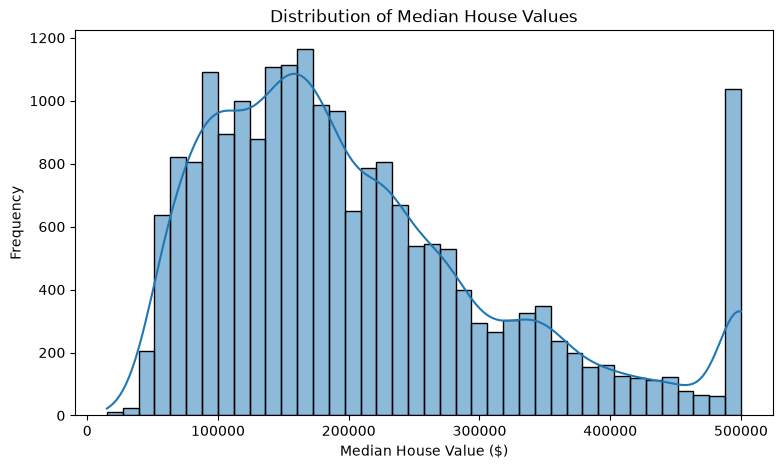

In [4]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df["median_house_value"],
    bins=40,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($)")
plt.ylabel("Frequency")

plt.show()

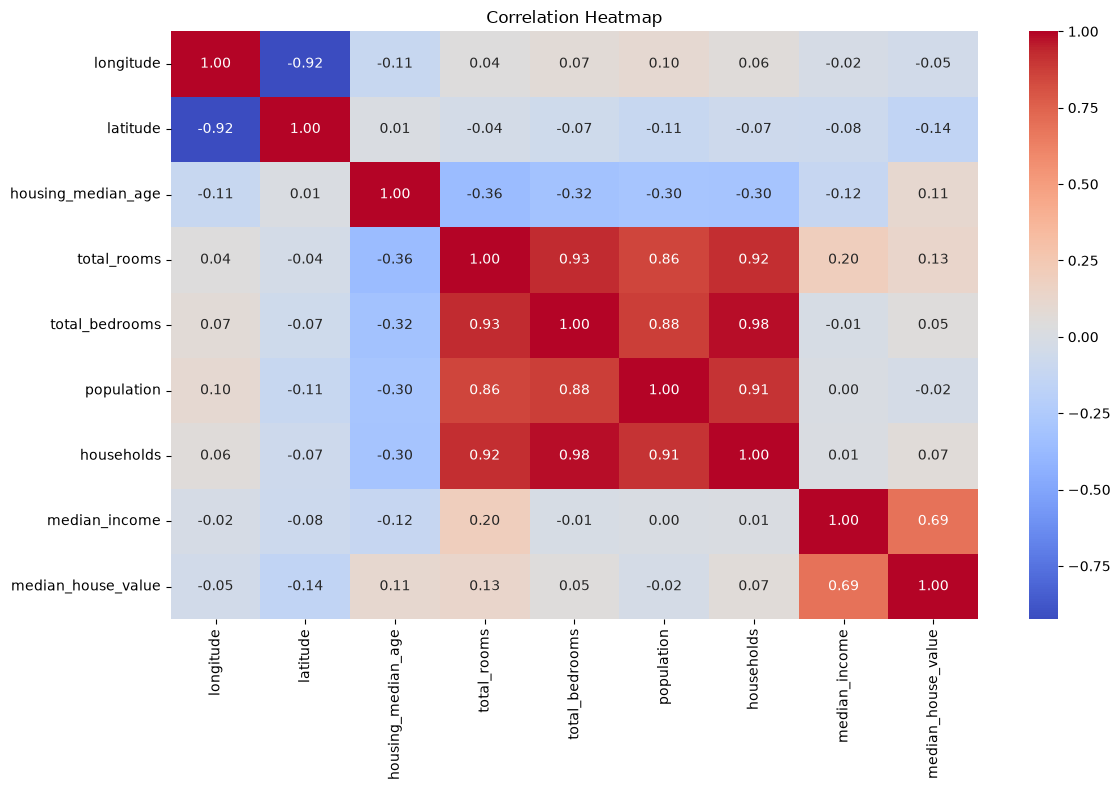

In [5]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.show()

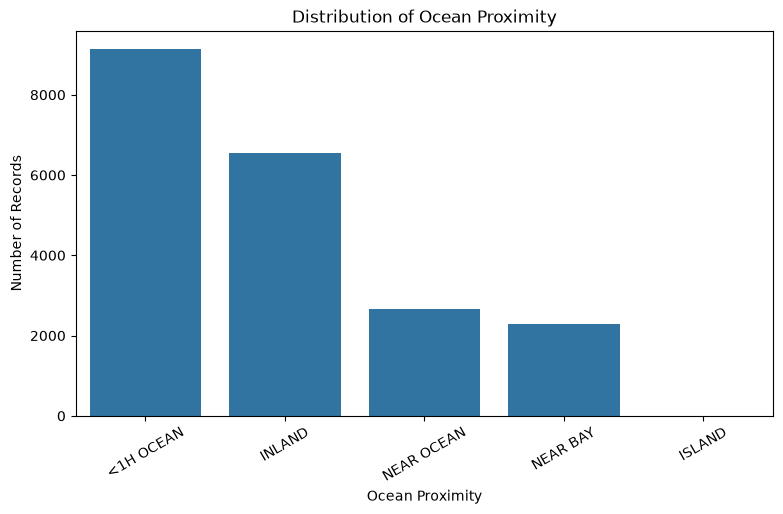

In [6]:
if "ocean_proximity" in df.columns:

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x="ocean_proximity",
        order=df["ocean_proximity"].value_counts().index
    )

    plt.title("Distribution of Ocean Proximity")
    plt.xlabel("Ocean Proximity")
    plt.ylabel("Number of Records")

    plt.xticks(rotation=30)
    plt.show()

In [7]:
# Create engineered features when their source columns exist

if {"total_rooms", "households"}.issubset(df.columns):
    df["rooms_per_household"] = (
        df["total_rooms"] / df["households"].replace(0, np.nan)
    )

if {"total_bedrooms", "total_rooms"}.issubset(df.columns):
    df["bedrooms_per_room"] = (
        df["total_bedrooms"] / df["total_rooms"].replace(0, np.nan)
    )

if {"population", "households"}.issubset(df.columns):
    df["population_per_household"] = (
        df["population"] / df["households"].replace(0, np.nan)
    )

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467


In [8]:
# Define target variable
target = "median_house_value"

# Separate features and target
X = df.drop(columns=[target])
y = df[target]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (20640, 12)
Target Shape: (20640,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.20, random_state=42)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (16512, 12)
Testing Data: (4128, 12)


In [11]:
# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()

categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']
Categorical Features: ['ocean_proximity']


In [12]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [13]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [14]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [15]:
interaction = PolynomialFeatures(
    degree=2,
    interaction_only=True,
    include_bias=False
)

In [ ]:
# Impute missing values before VIF calculation - Variance Inflation Factor
vif_imputer = SimpleImputer(strategy="median")

X_vif = pd.DataFrame(
    vif_imputer.fit_transform(X_train[numeric_features]),
    columns=numeric_features)

# Remove constant columns
X_vif = X_vif.loc[:, X_vif.nunique() > 1]

# Calculate VIF
vif_data = pd.DataFrame()

vif_data["Feature"] = X_vif.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif_data.sort_values(
    by="VIF",
    ascending=False
)

,Feature,VIF
4,total_bedrooms,49.750062
6,households,45.995683
3,total_rooms,18.701375
1,latitude,9.356559
0,longitude,9.040659
5,population,6.815947
9,bedrooms_per_room,2.774935
7,median_income,2.127241
8,rooms_per_household,1.774514
2,housing_median_age,1.259321


In [17]:
ols_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("interaction", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    )),
    ("model", LinearRegression())
])

In [18]:
ols_pipeline.fit(X_train, y_train)

print("OLS model training completed!")

OLS model training completed!


In [20]:
ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("interaction", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    )),
    ("model", Ridge())
])

ridge_params = {
    "model__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

In [21]:
ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

print("Best Ridge Parameters:", ridge_search.best_params_)
print("Best Ridge CV RMSE:", -ridge_search.best_score_)

Best Ridge Parameters: {'model__alpha': 10}
Best Ridge CV RMSE: 65496.026234217316


In [23]:
lasso_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("interaction", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    )),
    ("model", Lasso(max_iter=20000))
])

lasso_params = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100]
}

In [24]:
lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_search.fit(X_train, y_train)

print("Best Lasso Parameters:", lasso_search.best_params_)
print("Best Lasso CV RMSE:", -lasso_search.best_score_)

Best Lasso Parameters: {'model__alpha': 100}
Best Lasso CV RMSE: 65807.93824993187


In [25]:
# OLS predictions
ols_predictions = ols_pipeline.predict(X_test)

# Ridge predictions
ridge_predictions = ridge_search.best_estimator_.predict(X_test)

# Lasso predictions
lasso_predictions = lasso_search.best_estimator_.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [26]:
# Function to calculate regression metrics
def evaluate_model(y_true, y_pred):

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return rmse, mae, r2


# Evaluate OLS
ols_metrics = evaluate_model(y_test, ols_predictions)

# Evaluate Ridge
ridge_metrics = evaluate_model(y_test, ridge_predictions)

# Evaluate Lasso
lasso_metrics = evaluate_model(y_test, lasso_predictions)


# Create comparison table
comparison = pd.DataFrame({
    "Model": ["OLS", "Ridge", "Lasso"],
    "RMSE": [
        ols_metrics[0],
        ridge_metrics[0],
        lasso_metrics[0]
    ],
    "MAE": [
        ols_metrics[1],
        ridge_metrics[1],
        lasso_metrics[1]
    ],
    "R2 Score": [
        ols_metrics[2],
        ridge_metrics[2],
        lasso_metrics[2]
    ]
})

comparison

,Model,RMSE,MAE,R2 Score
0,OLS,71807.557633,45134.778725,0.606510
1,Ridge,67785.751687,45101.395864,0.649353
2,Lasso,65559.184814,45591.408353,0.672010


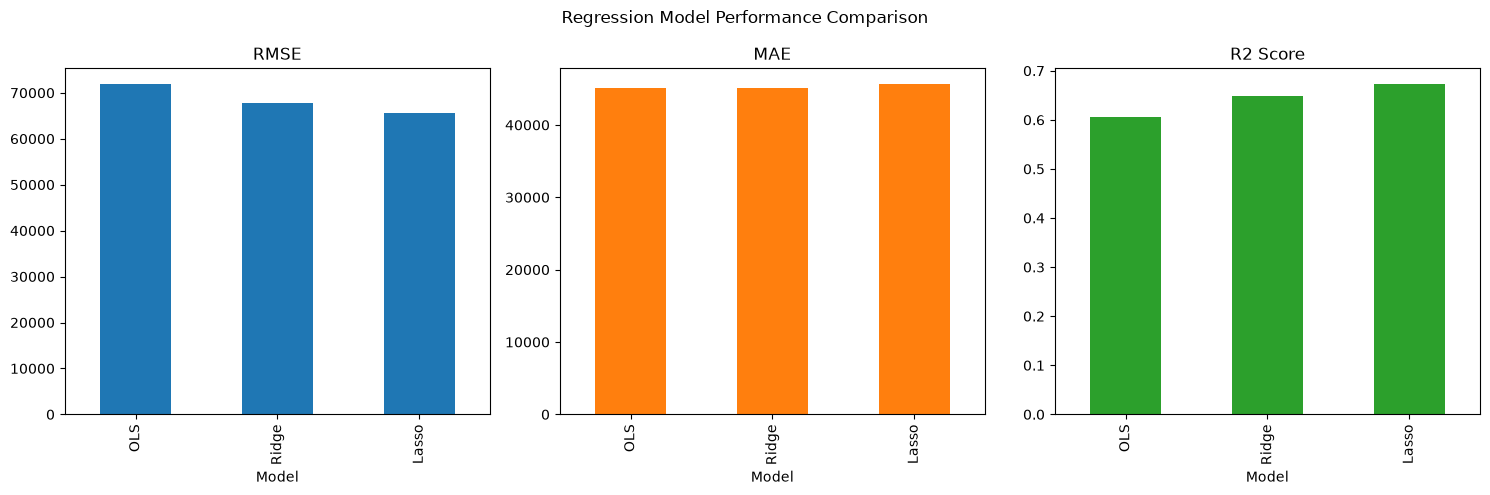

In [27]:
comparison.set_index("Model").plot(
    kind="bar",
    subplots=True,
    layout=(1, 3),
    figsize=(15, 5),
    legend=False
)

plt.suptitle("Regression Model Performance Comparison")
plt.tight_layout()

plt.show()

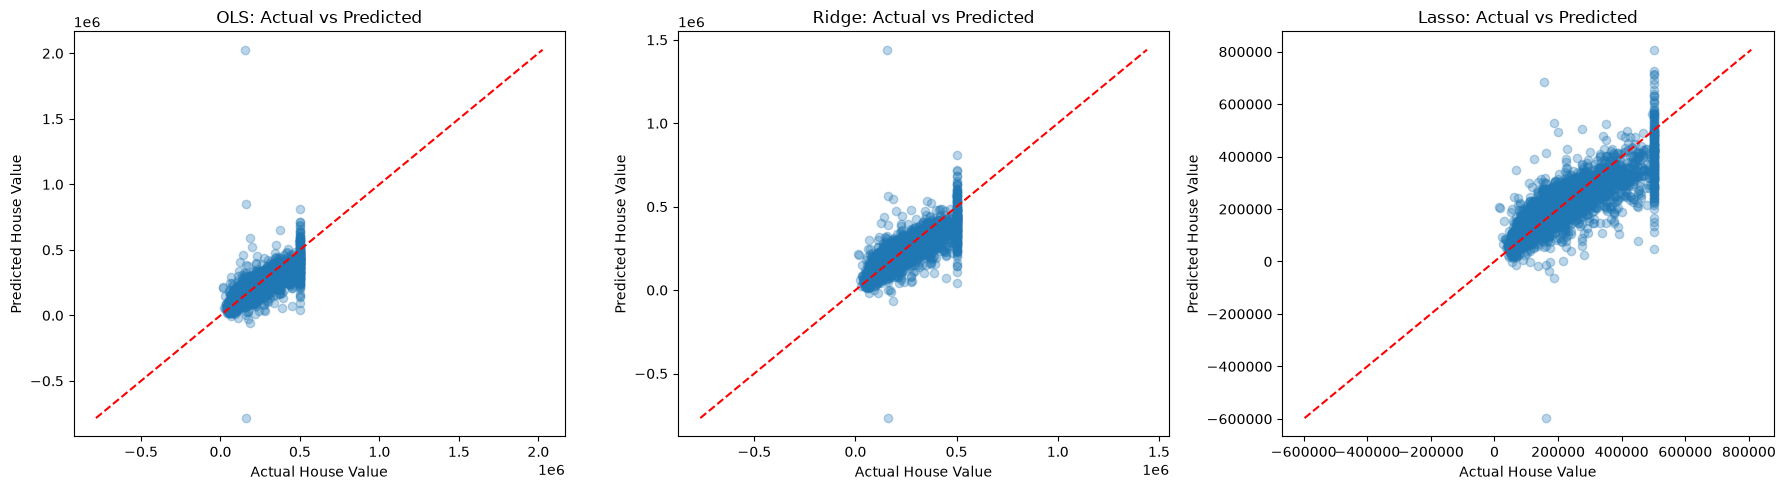

In [28]:
predictions = {
    "OLS": ols_predictions,
    "Ridge": ridge_predictions,
    "Lasso": lasso_predictions
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pred) in zip(axes, predictions.items()):

    ax.scatter(
        y_test,
        pred,
        alpha=0.3
    )

    # Perfect prediction reference line
    min_val = min(y_test.min(), pred.min())
    max_val = max(y_test.max(), pred.max())

    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        "r--"
    )

    ax.set_title(f"{name}: Actual vs Predicted")
    ax.set_xlabel("Actual House Value")
    ax.set_ylabel("Predicted House Value")

plt.tight_layout()
plt.show()

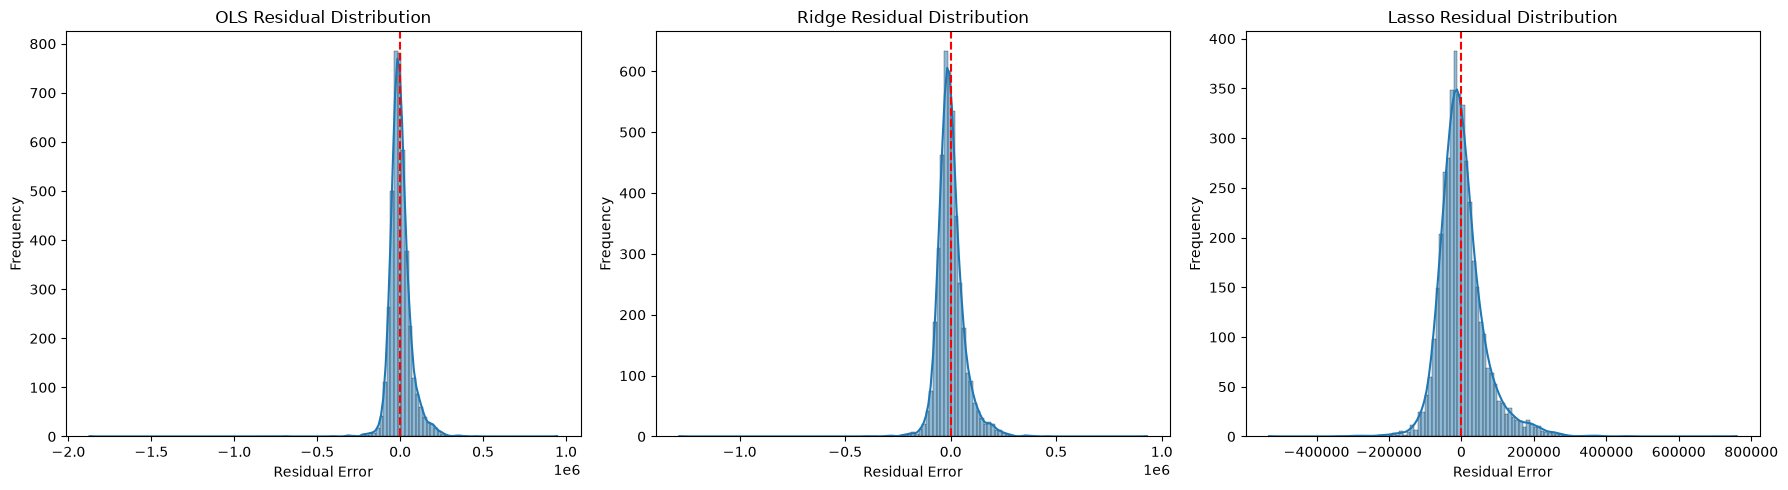

In [29]:
ols_residuals = y_test - ols_predictions

ridge_residuals = y_test - ridge_predictions

lasso_residuals = y_test - lasso_predictions


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

residual_data = {
    "OLS": ols_residuals,
    "Ridge": ridge_residuals,
    "Lasso": lasso_residuals
}

for ax, (name, residuals) in zip(
    axes, residual_data.items()
):

    sns.histplot(
        residuals,
        kde=True,
        ax=ax
    )

    ax.axvline(
        0,
        color="red",
        linestyle="--"
    )

    ax.set_title(f"{name} Residual Distribution")
    ax.set_xlabel("Residual Error")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

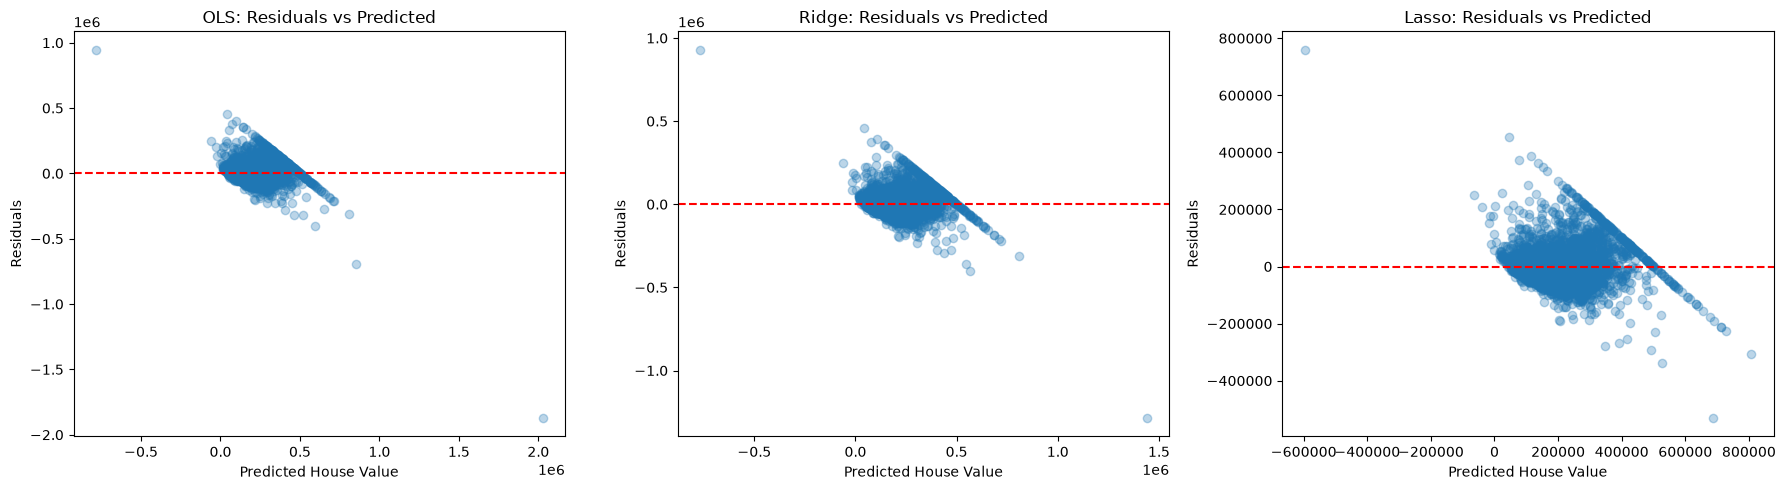

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pred) in zip(axes, predictions.items()):

    residuals = y_test - pred

    ax.scatter(pred, residuals, alpha=0.3)

    ax.axhline(0, color="red", linestyle="--")

    ax.set_title(f"{name}: Residuals vs Predicted")
    ax.set_xlabel("Predicted House Value")
    ax.set_ylabel("Residuals")

plt.tight_layout()
plt.show()

## 5. Conclusion

In this project, regression models were developed to predict
median house values using the California Housing dataset.

Data preprocessing included missing-value imputation,
categorical encoding, and feature standardization.

Feature engineering was performed to create additional
interaction features, while multicollinearity was examined
using correlation analysis and VIF.

Three regression algorithms were implemented:
Ordinary Least Squares, Ridge Regression, and Lasso Regression.

Ridge and Lasso hyperparameters were optimized using
GridSearchCV with 5-fold cross-validation.

The models were evaluated using RMSE, MAE, and R² scores.
Predicted-versus-actual plots and residual analysis were
also performed to examine prediction errors.

Based on the test-set evaluation, the best-performing
model was identified.

This project demonstrates an end-to-end regression
workflow using Python and Scikit-Learn.